<a href="https://colab.research.google.com/github/mmm10138/Machine-Learning/blob/main/FNO.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Learning ODE operator with a Fourier Neural Operator (FNO)

In this notebook we learn an operator related to an ODE by a Fourier Neural Operator (FNO).

In [1]:
import numpy as np
import matplotlib.pyplot as plt
import torch

np.random.seed(1)  # For reproducibility
torch.manual_seed(1)  # For reproducibility

In [2]:
# Consistent colors for the notebook figures
Q_COLOR = "#228833"       # Input function q: green
Y_REF_COLOR = "#225EA8"   # Euler reference y: dark blue
Y_PRED_COLOR = "#56B4E9"  # FNO prediction y: light blue
TRAIN_COLOR = "#0072B2"   # Training loss: blue
VAL_COLOR = "#D55E00"     # Validation/test loss: red-orange

## ODE definition


**ODE and Euler Method**

We consider the following ordinary differential equation (ODE):
$$
  \frac{dy}{dt} = q(t) - y(t),
$$
where $ q(t) $ is a given function of time, and $ y(t) $ is the unknown function we seek to solve. The goal is to find $ y(t) $ for $ t \in [0, T] $, given the initial condition:

$$
  y(0) = y_0.
$$

Reminder: when $q(t) = t$, we have an explicit solution. But in general we do not, so we will rely on a numerical method to compute the reference (approximate) solution.

**Euler's Method**

Euler's method is a simple numerical approach to solve first-order ODEs. We discretize the time interval $[0, T]$ into $ N_t $ equally spaced time points with a time step $ \Delta t $ given by:

$$
  \Delta t = \frac{T}{N_t - 1}.
$$

At each time step $ t_n $, the value of $ y(t) $ is updated using the formula:

$$
  y_{n+1} = y_n + \Delta t \cdot \left( q(t_n) - y_n \right),
$$
for $ n = 0, 1, 2, \dots, N_t - 2 $.

Here:
- $ y_n $ is the numerical approximation of $ y(t_n) $,
- $ t_n $ is the $ n $-th time point: $ t_n = n \Delta t $,
- $ q(t_n) $ is the value of the function $ q(t) $ at time $ t_n $.


## Computing the reference solution (Euler method)

In [3]:
def euler_ode_solver(y0, T, Nt, q):
    """
    Solves the ODE dy/dt = q(t) - y(t) using Euler's method.

    Args:
        y0 (float): Initial condition y(0).
        T (float): Time horizon.
        Nt (int): Number of time points.
        q (array-like): Array of q values at the time points.

    Returns:
        t (np.ndarray): Array of time points.
        y (np.ndarray): Array of y values at the time points.
    """
    # Time step
    dt = T / (Nt - 1)

    # Initialize arrays for time and solution
    t = np.linspace(0, T, Nt)
    y = np.zeros(Nt)

    # Set initial condition
    y[0] = y0

    # Euler method
    for n in range(1, Nt):
        y[n] = y[n-1] + dt * (q[n-1] - y[n-1])  # Euler step

    return y

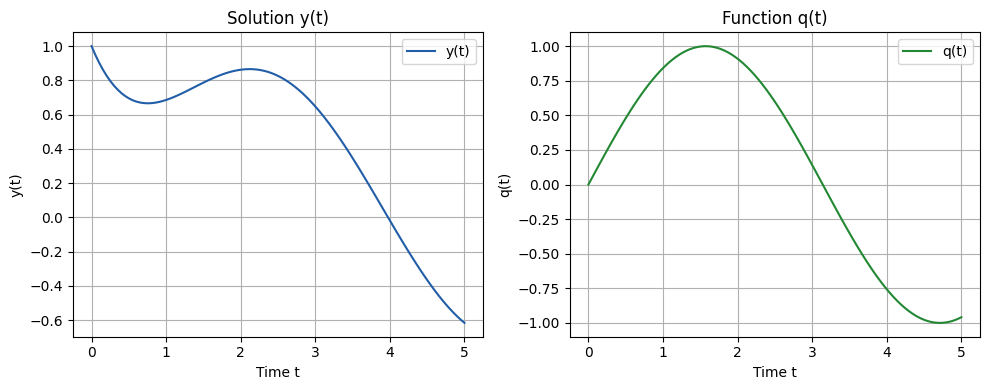

In [4]:
# Example usage
T = 5.0        # Time horizon
Nt = 100       # Number of time points
y0 = 1.0       # Initial condition
t = np.linspace(0, T, Nt)

# Example q(t) = sin(t)
q = np.sin(t)

# Solve the ODE
y = euler_ode_solver(y0, T, Nt, q)

# Plot the solution
# Create side-by-side subplots
fig, axs = plt.subplots(1, 2, figsize=(10, 4))

# Left: plot y(t)
axs[0].plot(t, y, label='y(t)', color=Y_REF_COLOR)
axs[0].set_xlabel('Time t')
axs[0].set_ylabel('y(t)')
axs[0].set_title('Solution y(t)')
axs[0].grid(True)
axs[0].legend()

# Right: plot q(t)
axs[1].plot(t, q, label='q(t)', color=Q_COLOR)
axs[1].set_xlabel('Time t')
axs[1].set_ylabel('q(t)')
axs[1].set_title('Function q(t)')
axs[1].grid(True)
axs[1].legend()

plt.tight_layout()
plt.show()

## Generating random functions on [0,T]

A Gaussian random field (GRF) is a collection of random variables indexed by a spatial domain, where every finite subset of points has a multivariate Gaussian distribution. The covariance structure of these random variables is defined by the kernel $k(x, x')$. The Matérn kernel or squared exponential kernel (also called the Radial Basis Function or RBF kernel) is often used to define the spatial correlation between different points in a GRF.

For the given kernel
$$
k(x, x') = \exp\left(-\frac{\|x - x'\|^2}{2 \ell^2}\right),
$$
the steps to sample a GRF are:

1. **Define a set of points**: Choose a set of spatial points $x_1, x_2, \ldots, x_N$ where you want to sample the function values.

2. **Construct the covariance matrix**: For these points, build an $N \times N$ covariance matrix $K$, where
$$
K_{ij} = k(x_i, x_j) = \exp\left(-\frac{\|x_i - x_j\|^2}{2 \ell^2}\right).
$$
This matrix defines the covariance between the values of the GRF at the sampled points.

3. **Sample from the multivariate Gaussian**: Once the covariance matrix is constructed, you can sample function values at the points by sampling from a multivariate normal distribution with mean zero and covariance matrix $K$. This will give you one realization of the GRF.


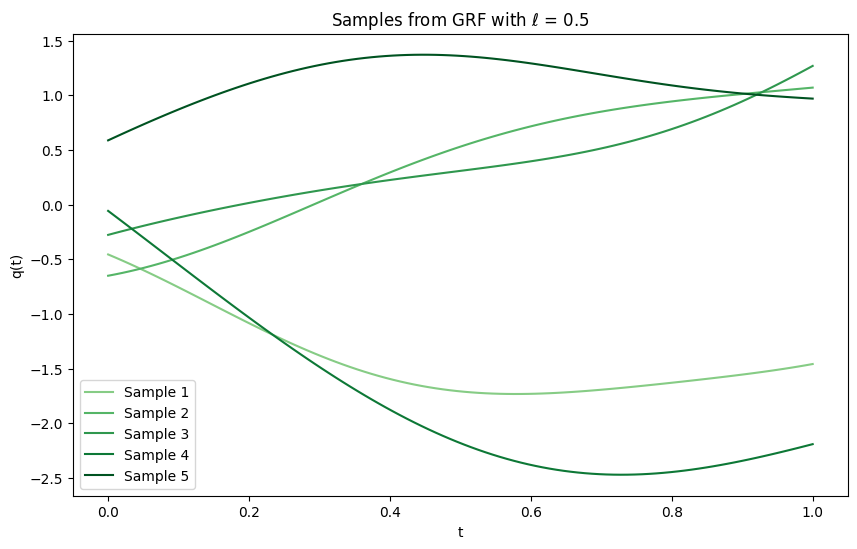

In [5]:
# Define the squared exponential (RBF) kernel
def rbf_kernel(x1, x2, ell):
    """Squared exponential kernel."""
    return np.exp(-np.sum((x1 - x2)**2) / (2 * ell**2))

# Generate covariance matrix using RBF kernel
def covariance_matrix(x, ell):
    """Generate covariance matrix for inputs x with length scale ell."""
    N = len(x)
    K = np.zeros((N, N))
    for i in range(N):
        for j in range(N):
            K[i, j] = rbf_kernel(x[i], x[j], ell)
    return K

# Sample from Gaussian Random Field
def sample_grf(x, ell, num_samples=1):
    """Sample from a Gaussian random field at locations x with length scale ell."""
    # Generate the covariance matrix for the spatial points
    K = covariance_matrix(x, ell)

    # Sample from multivariate normal with mean 0 and covariance matrix K
    mean = np.zeros(len(x))
    samples = np.random.multivariate_normal(mean, K, num_samples)
    return samples

# Parameters for the operator-learning example
T = 1.0       # Time domain [0, T]
y0 = 1.0      # Fixed initial condition
Nt_q = 100    # Number of time points
ell = 0.5     # Length scale of the input functions

# Generate time points
t_grid_q = np.linspace(0, T, Nt_q).reshape(-1, 1)

# Sample from the GRF
num_samples = 5  # Number of functions to sample
samples = sample_grf(t_grid_q, ell, num_samples=num_samples)

# Plot the sampled functions
plt.figure(figsize=(10, 6))
for i in range(num_samples):
    plt.plot(
          t_grid_q, samples[i],
          color=plt.cm.Greens(0.45 + 0.5 * i / max(1, num_samples - 1)),
          label=f'Sample {i+1}',
      )
plt.title(f'Samples from GRF with $\\ell$ = {ell}')
plt.xlabel('t')
plt.ylabel('q(t)')
plt.legend()
plt.show()

TODO:
- try small ell
- compare with really independent samples: covariance matrix = Identity matrix

## Generating samples of q

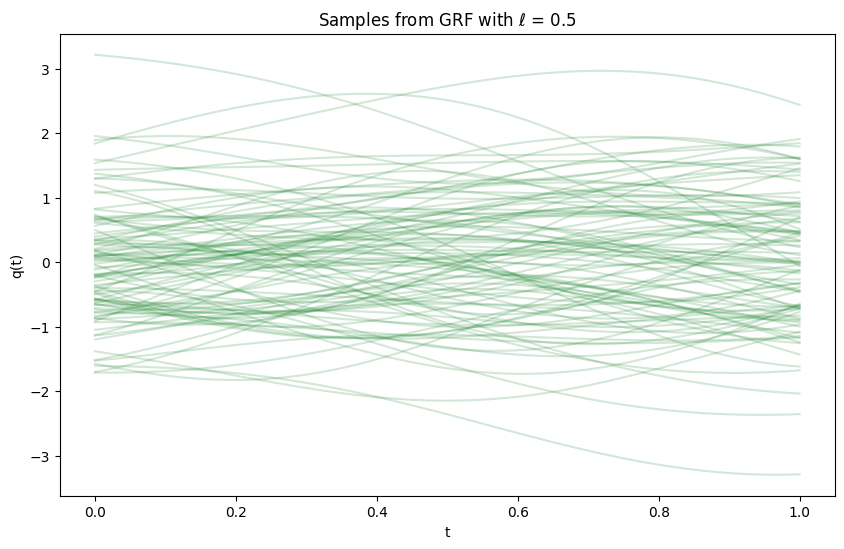

In [6]:
# Generate GRF samples
def generate_grf_samples(num_samples, grid_points, ell=0.1):
    return sample_grf(grid_points, ell=ell, num_samples=num_samples)

# Define the grid points (x-domain) for each source term g
num_t_q = Nt_q # same number of points as in the Euler code for simplicity

num_q = 100 # Number of q for training

q_samples = generate_grf_samples(num_q, t_grid_q, ell=ell)  # samples of q

# Plot the sampled functions
plt.figure(figsize=(10, 6))
for q in q_samples:
    plt.plot(t_grid_q, q, color=Q_COLOR, alpha=0.2)
plt.title(f'Samples from GRF with $\\ell$ = {ell}')
plt.xlabel('t')
plt.ylabel('q(t)')
plt.show()

In [7]:
# Function to solve the ODE for each source term q
def solve_ode_for_q(q, y0=1.0, T=1.0, Nt=100):
    # Assuming q is a function on the time domain
    y = euler_ode_solver(y0, T, Nt, q)
    return y

# Solve the ODE for each sampled q and store the results
y_solutions = [
    solve_ode_for_q(q, y0=y0, T=T, Nt=Nt_q)
    for q in q_samples
]  # List of ODE solutions

## Training, validation, and test functions

We use separate sets of input functions:

- The **training set** is used to update the network parameters.
- The **validation set** helps us assess training and choose settings.
- The **test set** is reserved for evaluation after those choices are made.

The split is by function: all time points of a given input function belong to the same set.

In [8]:
# Generate new functions that are independent of the training functions.
num_val = 20
num_test = 30

q_val_np = generate_grf_samples(num_val, t_grid_q, ell=ell)
q_test_np = generate_grf_samples(num_test, t_grid_q, ell=ell)

# Compute their Euler reference solutions.
y_val_np = np.array([
    solve_ode_for_q(q_i, y0=y0, T=T, Nt=Nt_q)
    for q_i in q_val_np
])

y_test_np = np.array([
    solve_ode_for_q(q_i, y0=y0, T=T, Nt=Nt_q)
    for q_i in q_test_np
])

/tmp/ipykernel_497/2661831950.py:3: UserWarning: Creating a tensor from a list of numpy.ndarrays is extremely slow. Please consider converting the list to a single numpy.ndarray with numpy.array() before converting to a tensor. (Triggered internally at /__w/pytorch/pytorch/torch/csrc/utils/tensor_new.cpp:252.)
  y_solutions = torch.tensor(y_solutions).clone().detach().float()


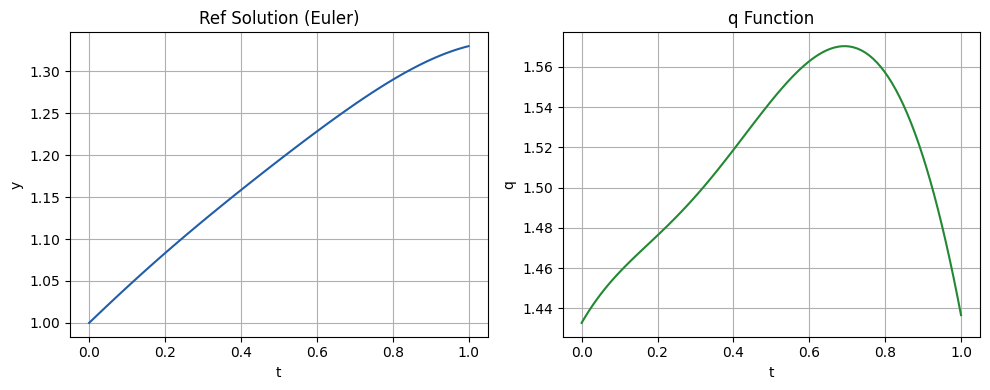

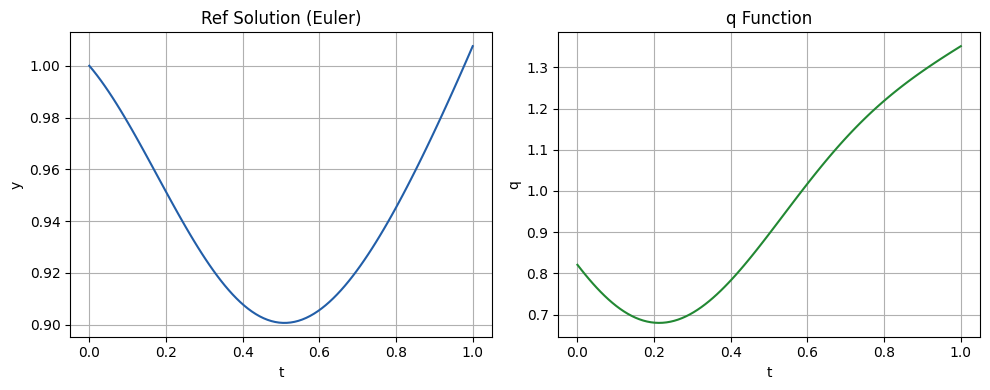

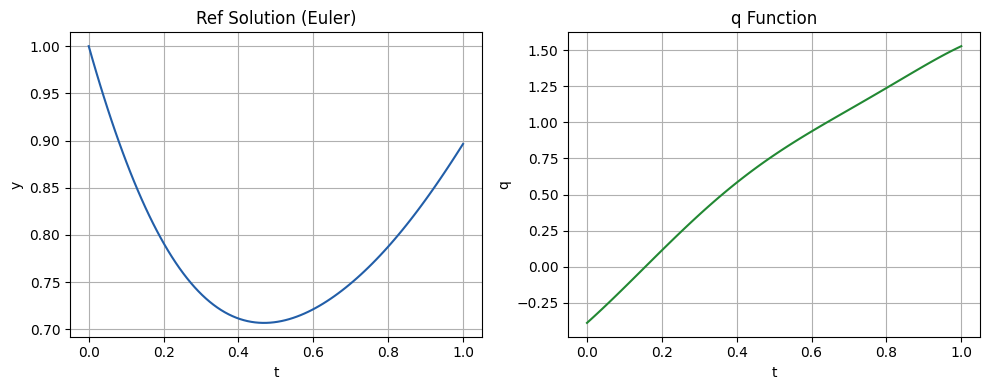

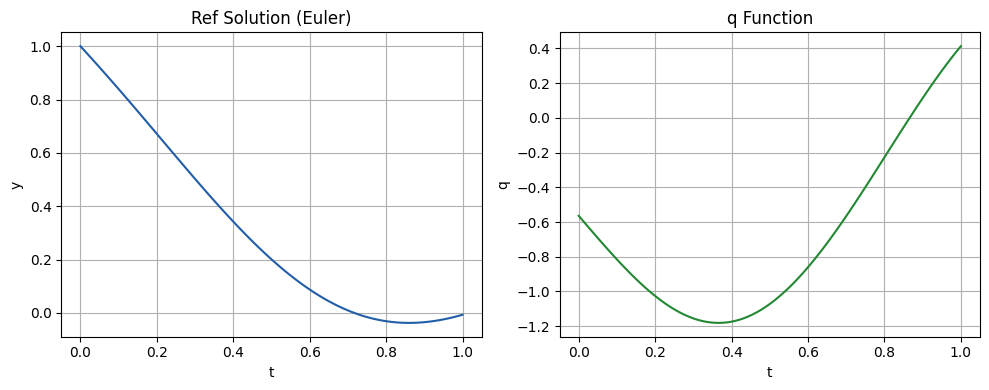

In [9]:
# Plot the solutions
q_samples = torch.tensor(q_samples).clone().detach().float()
y_solutions = torch.tensor(y_solutions).clone().detach().float()

for i_q in range(min(q_samples.shape[0], 4)):
    # Choose one q function from the pre-generated dataset
    q = q_samples[i_q].unsqueeze(0)

    # Solve the reference solution using Euler for comparison
    y_ref = y_solutions[i_q].detach().numpy()  # The reference solution for the selected q
    q_plot = q.squeeze().detach().numpy()       # Convert q to numpy for plotting

    # Create side-by-side plots
    fig, axs = plt.subplots(1, 2, figsize=(10, 4))

    # Left: y(t)
    axs[0].plot(t_grid_q, y_ref, color=Y_REF_COLOR)
    axs[0].set_title('Ref Solution (Euler)')
    axs[0].set_xlabel('t')
    axs[0].set_ylabel('y')
    axs[0].grid(True)

    # Right: q(t)
    axs[1].plot(t_grid_q, q_plot, color=Q_COLOR)
    axs[1].set_title('q Function')
    axs[1].set_xlabel('t')
    axs[1].set_ylabel('q')
    axs[1].grid(True)

    plt.tight_layout()
    plt.show()

# FNO for ODE

Here we implement a Fourier Neural Operator (FNO) for the ODE solution operator $q \mapsto y$.

At each time point, the FNO receives two input features: the value $q(t)$ and the coordinate $t$. The time coordinate tells the network where the initial condition is located. Providing the time coordinate helps the network distinguish the initial time, but it does not enforce $y(0)=y_0$ exactly.

Let $b$ be the batch size, $n$ the number of time points, $w$ the number of feature channels, and $L$ the number of Fourier layers. If $a$ denotes the two-channel input containing $q$ and $t$, the architecture is

$$
\begin{aligned}
x^{(0)} &= P(a) \in \mathbb{R}^{b \times w \times n}, \\
x^{(\ell+1)}
&= \sigma\!\left(
x^{(\ell)}
+ \mathcal{F}^{-1}\!\left(
R^{(\ell)} \cdot \mathcal{F}(x^{(\ell)})
\right)
+ W_\ell x^{(\ell)}
\right),
\quad \ell=0,\ldots,L-1, \\
y_{\mathrm{pred}} &= Q\!\left(x^{(L)}\right)
\in \mathbb{R}^{b \times n}.
\end{aligned}
$$

Here:

- $a \in \mathbb{R}^{b \times 2 \times n}$ contains $q$ and the time coordinate.
- $P$ is a pointwise lifting map from two channels to $w$ channels.
- $\mathcal{F}$ and $\mathcal{F}^{-1}$ denote the Fourier transform and its inverse. In the code, we retain only a finite number of modes.
- $R^{(\ell)} \in \mathbb{C}^{w \times w \times m}$ contains the learned spectral weights for the first $m$ nonnegative frequencies.
- $W_\ell$ is a pointwise affine map across channels.
- $\sigma$ is a nonlinear activation function.
- $Q$ is a pointwise projection to the predicted scalar solution.

The explicit term $x^{(\ell)}$ is a **residual connection**. The slides present a simplified update without this term and mention residual connections as a possible variant.

**Connection with the slides:** the slides use $v_\ell$ for the hidden representation and $d_v$ for its number of channels; here these are $x^{(\ell)}$ and $w$. The slides list channels last and omit the batch index, while the code uses `(batch, channels, grid points)`. The slides use a layer index in their iterative-update formulas; here $\ell$ is the layer index and $t$ denotes physical time.





## Fourier layer

We first implement the **Fourier layer**, which relies crucially on the **Discrete Fourier Transform**.

At each layer $\ell$, the hidden representation is  
$x^{(\ell)} \in \mathbb{R}^{b \times w \times n}$, where:

- $b$: batch size  
- $w$: number of feature channels  
- $n$: number of discretization points (e.g. time samples)

---

#### 1. Discrete Fourier Transform (DFT)

For each batch element $i \in \{1,\dots,b\}$ and channel $j \in \{1,\dots,w\}$,  
the 1D Discrete Fourier Transform along the grid dimension is:

$$
[\mathcal{F}(x^{(\ell)})]_{i,j,k}
=
\sum_{t=0}^{n-1}
x^{(\ell)}_{i,j,t}
\,
\exp\!\left(-\, 2\pi \iota \, \frac{k t}{n}\right),
\quad k = 0, \dots, n-1.
$$

Hence,
$$
\mathcal{F}(x^{(\ell)}) \in \mathbb{C}^{b \times w \times n}.
$$

---

#### 2. Real FFT and truncation

For real-valued input, the negative-frequency coefficients of the full DFT are determined by the nonnegative-frequency coefficients through conjugate symmetry. The code therefore uses `rfft`, which stores only the nonnegative frequencies:

$$
\mathcal{F}_{\mathrm{real}}(x^{(\ell)})
\in
\mathbb{C}^{b \times w \times (\lfloor n/2 \rfloor+1)}.
$$

We retain the first $m$ of these coefficients:

$$
\mathcal{F}_m(x^{(\ell)})
=
\mathcal{F}_{\mathrm{real}}(x^{(\ell)})_{:\,,\,:\,,\,0:m}
\in \mathbb{C}^{b \times w \times m}.
$$

The remaining stored coefficients are set to zero before applying the inverse transform.

---

#### 3. Spectral multiplication

Each layer $\ell$ has learnable complex weights

$$
R^{(\ell)} \in \mathbb{C}^{w \times w \times m}.
$$

For each retained mode $k=0,\ldots,m-1$, the layer applies a learned linear map across channels:

$$
\widehat{z}^{(\ell)}_{i,:,k}
=
R^{(\ell)}_{:,:,k}
[\mathcal{F}_m(x^{(\ell)})]_{i,:,k}.
$$

The code stores the real and imaginary parts of these weights separately.

---

#### 4. Inverse real FFT

We place the transformed coefficients in a one-sided spectrum of size $\lfloor n/2 \rfloor+1$ and set the remaining entries to zero. The inverse real FFT, `irfft`, reconstructs the matching negative-frequency coefficients and returns a real-valued signal:

$$
z^{(\ell)} \in \mathbb{R}^{b \times w \times n}.
$$

The zero-frequency coefficient and, when present, the Nyquist-frequency coefficient are special: their imaginary parts do not contribute to the real inverse transform.

This is equivalent to the full-spectrum description in the slides, where positive- and negative-frequency multipliers are matched by conjugate symmetry.

---

#### 5. Summary

In each Fourier layer:

1. Apply `rfft` along the time-grid axis.
2. Multiply the first $m$ nonnegative-frequency coefficients by learned channel matrices.
3. Set the remaining stored coefficients to zero.
4. Apply `irfft` to return to the time grid.

The FFT is an efficient algorithm for computing the DFT.

In [17]:
import torch.nn as nn
import torch.nn.functional as F

class SpectralConv1d(nn.Module):
    """
    1D Fourier layer (Spectral Convolution):
    Performs a Discrete Fourier Transform (DFT) along the last dimension,
    multiplies the first `modes` complex Fourier coefficients by learnable weights,
    zeroes out higher frequencies, and applies the inverse DFT.

    Input:  (batch, in_channels, n)
    Output: (batch, out_channels, n)
    """
    def __init__(self, in_channels, out_channels, modes):
        super().__init__()
        self.in_ch = in_channels
        self.out_ch = out_channels
        self.modes = modes  # number of retained low-frequency modes

        # Learnable complex weights for the first `modes` frequencies
        # Stored as separate real and imaginary parts
        # Shape: (out_channels, in_channels, modes)
        self.scale = 1 / (in_channels * out_channels)
        self.weights_real = nn.Parameter(self.scale * torch.randn(out_channels, in_channels, modes))
        self.weights_imag = nn.Parameter(self.scale * torch.randn(out_channels, in_channels, modes))

    def compl_mul1d(self, input_ft, weights_real, weights_imag):
        """
        Performs complex multiplication of truncated Fourier coefficients
        with learnable complex weights R = W_real + i W_imag.

        input_ft: (batch, in_ch, modes)
        weights:  (out_ch, in_ch, modes)
        output:   (batch, out_ch, modes)
        """
        input_real, input_imag = input_ft
        out_real = torch.einsum('bim,oim->bom', input_real, weights_real) - torch.einsum('bim,oim->bom', input_imag, weights_imag)
        out_imag = torch.einsum('bim,oim->bom', input_real, weights_imag) + torch.einsum('bim,oim->bom', input_imag, weights_real)
        return out_real, out_imag

    def forward(self, x):
        """
        Forward pass:
        1. Compute 1D DFT (rfft) along the last axis.
        2. Keep the first `modes` frequencies.
        3. Multiply them by complex weights (learned).
        4. Place the results in a zero-filled one-sided spectrum.
        5. Apply inverse DFT (irfft) to get real signal.

        x: (batch, in_ch, n)
        returns: (batch, out_ch, n)
        """
        batchsize, _, n = x.shape  # x: (b, in_ch, n)

        # 1. Forward real FFT along the time-grid dimension
        #Apply the real FFT along the last dimension.
        x_ft = torch.fft.rfft(x, n=n, dim=-1) # Shape: (batch, in_ch, n//2 + 1)  # (b, in_ch, n//2 + 1)

        # 2. Keep the available low-frequency modes
        modes = min(self.modes, x_ft.shape[-1])  # m
        #Keep the first `modes` coefficients along the last dimension.
        x_ft_trunc = x_ft[...,:modes] # Shape: (batch, in_ch, modes)           # (b, in_ch, m)

        # 3. Apply learned channel mixing at each retained mode
        x_real = x_ft_trunc.real  # (b, in_ch, m)
        x_imag = x_ft_trunc.imag  # (b, in_ch, m)

        # Each weight tensor has shape (out_ch, in_ch, m).
        out_real, out_imag = self.compl_mul1d(
            (x_real, x_imag),
            self.weights_real[..., :modes],
            self.weights_imag[..., :modes],
        )
        # out_real and out_imag: (b, out_ch, m)

        # 4. Place the results in a zero-filled one-sided spectrum
        full_ft = torch.zeros(
            batchsize, self.out_ch, x_ft.shape[-1],
            dtype=torch.cfloat, device=x.device
        )  # (b, out_ch, n//2 + 1)

        #Combine out_real and out_imag into complex coefficients,
        # and place them in the first `modes` entries of full_ft.
        full_ft[..., :modes] = out_real[..., :modes] + 1j * out_imag[..., :modes]

        # 5. Return to the time grid
        # TODO: Apply the inverse real FFT along the last dimension.
        # Specify the output length n.
        x_out = torch.fft.irfft(full_ft,n=n,dim=-1)  # (b, out_ch, n)
        return x_out


## Full architecture

Next, we implement the full architecture as described before, using our Fourier layer.

The first performs an extra linear transformation to respectively increase the input's dimension in the following way. Likewise, the last layer reduces the dimension before the final output.

For convenience, they are implemented using `Conv1d(kernel_size=1)`. The fact that the kernel size is 1 means that there are actually no interactions between neighboring points, so it is not really doing a convolution.

---

### What `Conv1d(kernel_size=1)` does

For a tensor $x \in \mathbb{R}^{b \times c_{\text{in}} \times n}$,  
the layer `nn.Conv1d(c_in, c_out, kernel_size=1)` computes:

$$
y_{b,o,j} = \sum_{i=1}^{c_{\text{in}}} W_{o,i,1}\, x_{b,i,j} + b_o,
$$

where:
- $b$: batch index  
- $o$: output channel  
- $i$: input channel  
- $j$: grid point (spatial location)

Hence, it acts as a **learned linear projection across channels**,  
but does **not mix information between grid points**.


---

### Lifting operator $P$

At each time point $t_j$, the input contains two features:

$$
a_i(t_j)=
\begin{bmatrix}
q_i(t_j) \\
t_j
\end{bmatrix}.
$$

The lifting layer applies the same affine map independently at each time point:

$$
x^{(0)}_{i,:,j}
=
A_0 a_i(t_j)+b_0,
\qquad
A_0\in\mathbb{R}^{w\times 2},
\quad
b_0\in\mathbb{R}^{w}.
$$

Thus the lifted representation has shape

$$
x^{(0)}=P(a)\in\mathbb{R}^{b\times w\times n}.
$$

In the code, `input_conv` is a `Conv1d` with kernel size 1. It mixes the two input channels at each time point but does not mix different time points:

```python
self.input_conv = nn.Conv1d(2, width, kernel_size=1)
```

---

### Projection operator $Q$

The final operator \(Q\) performs a **pointwise nonlinear projection** from the feature space back to a scalar output function.

For each sample \(x_i^{(L)}(\cdot) \in \mathbb{R}^{w \times n}\) and each grid point \(t_j\):

1. The first linear map acts across the $w$ feature channels, followed by a nonlinearity $\sigma$:
   $$
   h_{i,:,j} = \sigma(A_1\, x_i^{(L)}(:,j) + b_1),
   \quad A_1 \in \mathbb{R}^{128 \times w}, \quad b_1 \in \mathbb{R}^{128}.
   $$

2. The second linear map projects the result to a single output channel:
   $$
   y_{i,j}^{\text{pred}} = A_2\, h_{i,:,j} + b_2,
   \quad A_2 \in \mathbb{R}^{1 \times 128}, \quad b_2 \in \mathbb{R}.
   $$

Combining both steps, the projection operator can be written as:
$$
y_{\text{pred}} = Q(x^{(L)}) = A_2\, \sigma(A_1\, x^{(L)} + b_1) + b_2,
$$
where all operations are applied **independently at each grid point** (i.e., there is no spatial coupling).

This produces the final output
$$
y_{\text{pred}} \in \mathbb{R}^{b \times n},
$$
where:
- $b$ is the batch size,  
- $n$ is the number of discretization points (e.g., time or space),  
- each $y_{\text{pred}}[i, :]$ represents the predicted function for sample $i$.

The last layers are implemented as:

```python
self.output_conv1 = nn.Conv1d(width, 128, kernel_size=1)
self.output_conv2 = nn.Conv1d(128, 1, kernel_size=1)
```


In [14]:
class FNO1d(nn.Module):
    def __init__(self, modes, width, T, n_layers=4):
        super().__init__()
        self.modes = modes
        self.width = width
        self.T = T
        self.n_layers = n_layers

        # Input channels: q(t) and the time coordinate t
        # Map the two input channels to `width` channels at each time point.
        # Use a Conv1d with kernel_size=1.
        self.input_conv = nn.Conv1d(2, width, kernel_size=1)

        # spectral layers + pointwise conv (local)
        self.spectral_layers = nn.ModuleList()
        self.w_convs = nn.ModuleList()
        for _ in range(n_layers):
            self.spectral_layers.append(SpectralConv1d(width, width, modes))
            # small local conv for mixing (like W in FNO paper)
            self.w_convs.append(nn.Conv1d(width, width, kernel_size=1))

        # projection to output (1 channel)
        self.output_conv1 = nn.Conv1d(width, 128, kernel_size=1)
        self.output_conv2 = nn.Conv1d(128, 1, kernel_size=1)

    def forward(self, x):
        """
        x: values of q, with shape (batch, n) or (batch, 1, n)
        returns: predicted solution, with shape (batch, n)
        """
        if x.dim() == 2:
            x = x.unsqueeze(1)  # (b, n) -> (b, 1, n)

        batch_size, _, n = x.shape  # x: (b, 1, n)

        # Construct the time coordinates on the same grid as the input.
        t = torch.linspace(
            0, self.T, n, device=x.device, dtype=x.dtype
        )  # (n,)

        t = t.view(1, 1, n).expand(batch_size, 1, n)  # (b, 1, n)

        #Concatenate q and t along the channel dimension.
        x = torch.cat((x,t), dim=1) # Shape: (batch, 2, n)

        # Lift the two input channels to width w.
        x = self.input_conv(x)  # (b, w, n)

        for spec, local_layer in zip(self.spectral_layers, self.w_convs):
            x_spec = spec(x)   # (b, w, n): spectral path
            x_local = local_layer(x)     # (b, w, n): pointwise path

            # Add both paths and the residual, then apply the activation.
            # Add the spectral path, the local path, and the residual x;
            # then apply the GELU activation.
            x = F.gelu(x_spec+x_local+x)  # (b, w, n)

        # Project the features back to a scalar function.
        x = F.gelu(self.output_conv1(x))  # (b, 128, n)
        x = self.output_conv2(x)         # (b, 1, n)

        return x.squeeze(1)  # (b, n)

## Training FNO

Now we train the FNO on our example of ODE.

In [18]:
# Model and training settings
device = 'cuda' if torch.cuda.is_available() else 'cpu'
modes = 16
width = 32
n_layers = 3

learning_rate = 1e-3
batch_size = 16
n_epochs = 200
eval_every = 10

# Move the datasets to the chosen device.
# q and y are the training functions and their Euler references.
q = q_samples.to(device)
y = y_solutions.to(device)

q_val = torch.tensor(q_val_np, dtype=torch.float32, device=device)
y_val = torch.tensor(y_val_np, dtype=torch.float32, device=device)

q_test = torch.tensor(q_test_np, dtype=torch.float32, device=device)
y_test = torch.tensor(y_test_np, dtype=torch.float32, device=device)


def evaluate_mse(model, inputs, references):
    """Mean squared error over functions and time-grid points."""
    model.eval()
    with torch.no_grad():
        predictions = model(inputs)
        mse = torch.mean((predictions - references) ** 2)
    return mse.item()


def train_one_model(seed, verbose=True):
    """Train one FNO and evaluate it on fixed training and validation sets."""
    torch.manual_seed(seed)

    model = FNO1d(
        modes=modes, width=width, T=T, n_layers=n_layers
    ).to(device)

    optimizer = torch.optim.Adam(model.parameters(), lr=learning_rate)
    loss_fn = nn.MSELoss()

    eval_epochs = []
    train_mses = []
    val_mses = []

    for epoch in range(n_epochs):
        model.train()
        permutation = torch.randperm(q.shape[0], device=device)

        for i in range(0, q.shape[0], batch_size):
            indices = permutation[i:i + batch_size]  # (b,)
            q_batch = q[indices]                     # (b, n)
            y_batch = y[indices]                     # (b, n)

            predictions = model(q_batch)             # (b, n)
            #Compute the loss between the predictions and reference solutions.
            loss = loss_fn(predictions,y_batch)    # scalar

            optimizer.zero_grad()
            loss.backward()
            optimizer.step()

        # Evaluate both sets with the same model after the epoch.
        if (epoch + 1) % eval_every == 0 or epoch == n_epochs - 1:
            train_mse = evaluate_mse(model, q, y)
            val_mse = evaluate_mse(model, q_val, y_val)

            eval_epochs.append(epoch + 1)
            train_mses.append(train_mse)
            val_mses.append(val_mse)

            if verbose:
                print(
                    f"Epoch {epoch + 1:3d}/{n_epochs} | "
                    f"train MSE: {train_mse:.3e} | "
                    f"validation MSE: {val_mse:.3e}"
                )

    return model, eval_epochs, train_mses, val_mses


# Main run
model, eval_epochs, train_mses, val_mses = train_one_model(seed=1)

Epoch  10/200 | train MSE: 5.138e-03 | validation MSE: 7.013e-03
Epoch  20/200 | train MSE: 8.887e-04 | validation MSE: 1.491e-03
Epoch  30/200 | train MSE: 2.142e-04 | validation MSE: 3.364e-04
Epoch  40/200 | train MSE: 1.331e-04 | validation MSE: 2.190e-04
Epoch  50/200 | train MSE: 6.749e-05 | validation MSE: 1.382e-04
Epoch  60/200 | train MSE: 5.011e-05 | validation MSE: 1.005e-04
Epoch  70/200 | train MSE: 3.720e-05 | validation MSE: 8.266e-05
Epoch  80/200 | train MSE: 3.536e-05 | validation MSE: 7.306e-05
Epoch  90/200 | train MSE: 3.306e-05 | validation MSE: 7.259e-05
Epoch 100/200 | train MSE: 3.052e-05 | validation MSE: 6.538e-05
Epoch 110/200 | train MSE: 3.990e-05 | validation MSE: 7.546e-05
Epoch 120/200 | train MSE: 1.965e-05 | validation MSE: 4.810e-05
Epoch 130/200 | train MSE: 2.303e-05 | validation MSE: 4.344e-05
Epoch 140/200 | train MSE: 1.409e-05 | validation MSE: 3.953e-05
Epoch 150/200 | train MSE: 1.794e-05 | validation MSE: 4.530e-05
Epoch 160/200 | train MSE

### Tensor shapes in the FNO

The following cell follows a small batch through the lifting operation and the first Fourier layer. It shows how the time-grid dimension changes under the real FFT and how the channel dimensions are used.

The remaining Fourier layers have the same input and output shapes. The final line shows the output shape of the complete model.

In [21]:
def show_fno_shapes(model, q_batch):
    """Show the main tensor shapes for one batch and one Fourier layer."""
    model.eval()

    with torch.no_grad():
        # Input function values: one row per function.
        print(f"Input q:                   {tuple(q_batch.shape)}")

        # Add the channel dimension.
        x = q_batch.unsqueeze(1)
        batch_size, _, n = x.shape
        print(f"Input q with channel:      {tuple(x.shape)}")

        # Construct and add the time-coordinate channel.
        t = torch.linspace(
            0, model.T, n, device=x.device, dtype=x.dtype
        )
        t = t.view(1, 1, n).expand(batch_size, 1, n)
        print(f"Time coordinate t:         {tuple(t.shape)}")

        # Concatenate q and t along the channel dimension.
        x = torch.cat((x,t), dim=1)  # (b, 2, n)
        print(f"Input channels (q, t):     {tuple(x.shape)}")

        # Pointwise lifting.
        x = model.input_conv(x)
        print(f"After lifting:             {tuple(x.shape)}")

        # Inspect the first Fourier layer.
        spectral_layer = model.spectral_layers[0]
        local_layer = model.w_convs[0]

        # Apply the real FFT along the last dimension.
        x_ft = torch.fft.rfft(x,n=n, dim=-1)   # Shape: (batch, in_ch, n//2 + 1)
        print(f"After rfft:                {tuple(x_ft.shape)}")

        modes = min(spectral_layer.modes, x_ft.shape[-1])
        # Keep the first `modes` coefficients along the last dimension.
        x_ft_trunc = x_ft[...,:modes] # Shape: (batch, in_ch, modes)
        print(f"Retained Fourier modes:    {tuple(x_ft_trunc.shape)}")

        weights_real = spectral_layer.weights_real[..., :modes]
        weights_imag = spectral_layer.weights_imag[..., :modes]
        print(f"Spectral weights:          {tuple(weights_real.shape)}")

        # Apply the learned channel mixing at each retained mode.
        out_real, out_imag = spectral_layer.compl_mul1d(
            (x_ft_trunc.real, x_ft_trunc.imag),
            weights_real,
            weights_imag,
        )
        print(f"After spectral mixing:     {tuple(out_real.shape)}")

        # Place the coefficients in the one-sided spectrum.
        full_ft = x_ft.new_zeros(
            batch_size, spectral_layer.out_ch, x_ft.shape[-1]
        )
        # Combine out_real and out_imag into complex coefficients,
        # and place them in the first `modes` entries of full_ft.
        full_ft[..., :modes] = out_real+1j*out_imag
        print(f"One-sided output spectrum: {tuple(full_ft.shape)}")

        x_spec = torch.fft.irfft(full_ft, n=n, dim=-1)
        x_local = local_layer(x)
        print(f"After inverse rfft:        {tuple(x_spec.shape)}")
        print(f"Pointwise path:            {tuple(x_local.shape)}")

        x_next = F.gelu(x_spec + x_local + x)
        print(f"After first FNO update:    {tuple(x_next.shape)}")

        # Run the complete model to show its final output shape.
        y_pred = model(q_batch)
        print(f"Full model output:         {tuple(y_pred.shape)}")


# Inspect a batch of two training functions.
show_fno_shapes(model, q[:2])

Input q:                   (2, 100)
Input q with channel:      (2, 1, 100)
Time coordinate t:         (2, 1, 100)
Input channels (q, t):     (2, 2, 100)
After lifting:             (2, 32, 100)
After rfft:                (2, 32, 51)
Retained Fourier modes:    (2, 32, 16)
Spectral weights:          (32, 32, 16)
After spectral mixing:     (2, 32, 16)
One-sided output spectrum: (2, 32, 51)
After inverse rfft:        (2, 32, 100)
Pointwise path:            (2, 32, 100)
After first FNO update:    (2, 32, 100)
Full model output:         (2, 100)


### Training and validation errors

Both curves below are evaluated on fixed sets of complete functions after each selected epoch. They measure the mean squared error over functions and time points.

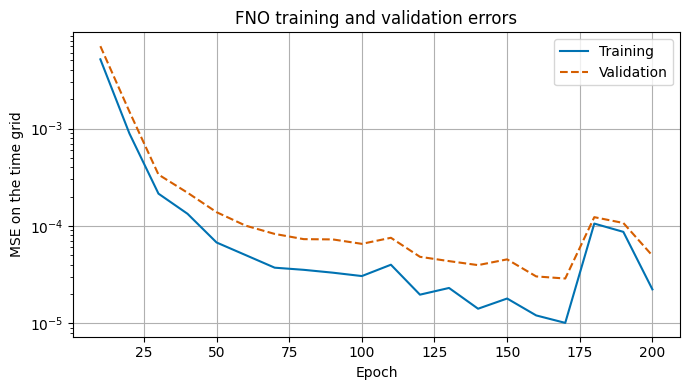

In [22]:
plt.figure(figsize=(7, 4))
plt.semilogy(
    eval_epochs, train_mses,
    color=TRAIN_COLOR, linestyle="-", label="Training"
)
plt.semilogy(
    eval_epochs, val_mses,
    color=VAL_COLOR, linestyle="--", label="Validation"
)

plt.xlabel("Epoch")
plt.ylabel("MSE on the time grid")
plt.title("FNO training and validation errors")
plt.grid(True)
plt.legend()
plt.tight_layout()
plt.show()

## Test on training samples

In [23]:
def plot_pred_and_q(q, y_ref, y_pred, t_grid_q, title_prefix="Sample"):
    """
    Plots model-predicted vs reference y(t), and the corresponding q(t), side by side.

    Args:
        q: 1D array or tensor — the input q(t) function.
        y_ref: 1D array or tensor — the reference solution y(t).
        y_pred: 1D array or tensor — the predicted solution y(t).
        t_grid_q: 1D array or tensor — time/grid points.
        title_prefix: Optional string for titles.
    """
    # Convert tensors to numpy for plotting
    if torch.is_tensor(q): q = q.detach().cpu().numpy()
    if torch.is_tensor(y_ref): y_ref = y_ref.detach().cpu().numpy()
    if torch.is_tensor(y_pred): y_pred = y_pred.detach().cpu().numpy()
    if torch.is_tensor(t_grid_q): t_grid_q = t_grid_q.detach().cpu().numpy()

    # Create side-by-side subplots
    fig, axs = plt.subplots(1, 2, figsize=(10, 4))

    # Left: predicted vs reference y
    axs[0].plot(
        t_grid_q, y_ref,
        color=Y_REF_COLOR, linestyle='-',
        label='Euler reference',
    )
    axs[0].plot(
        t_grid_q, y_pred,
        color=Y_PRED_COLOR, linestyle='--',
        label='FNO prediction',
    )
    axs[0].set_title(f'{title_prefix} — Predicted vs Ref Solution')
    axs[0].set_xlabel('t')
    axs[0].set_ylabel('y')
    axs[0].legend()
    axs[0].grid(True)

    # Right: q(t)
    axs[1].plot(t_grid_q, q, color=Q_COLOR)
    axs[1].set_title(f'{title_prefix} — q Function')
    axs[1].set_xlabel('t')
    axs[1].set_ylabel('q')
    axs[0].legend()
    axs[1].grid(True)

    plt.tight_layout()
    plt.show()

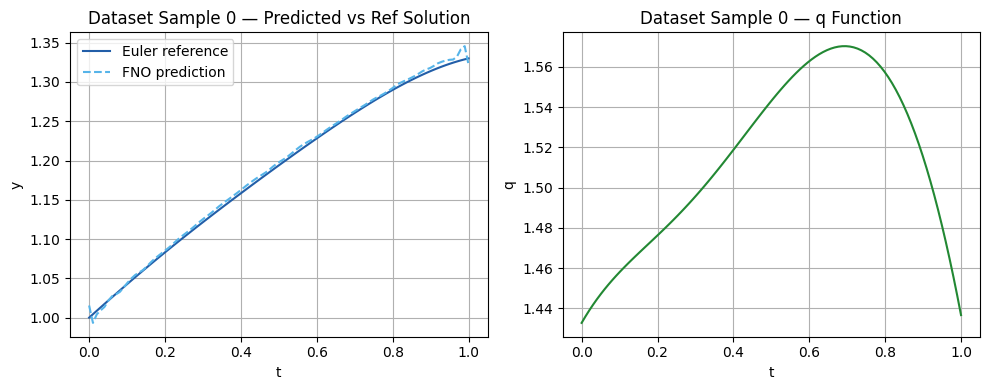

In [24]:
i = 0
model.eval()
with torch.no_grad():
    q_i = q[i]
    q0 = q_i.unsqueeze(0).to(device)  # (1, n)
    y_pred = model(q0).cpu().numpy().squeeze()
    y_ref = y[i].cpu().numpy() if torch.is_tensor(y) else y[i]

# Use the plotting helper
plot_pred_and_q(q_i, y_ref, y_pred, t_grid_q, title_prefix=f"Dataset Sample {i}")

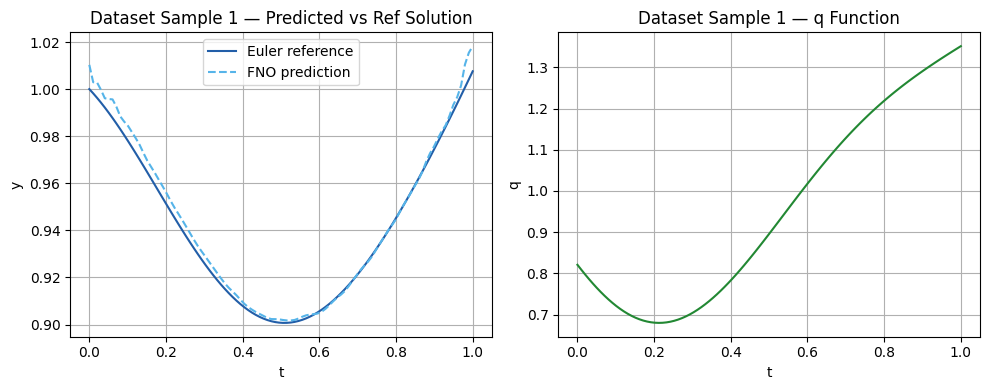

In [25]:
i = 1
model.eval()
with torch.no_grad():
    q_i = q[i]
    q0 = q_i.unsqueeze(0).to(device)  # (1, n)
    y_pred = model(q0).cpu().numpy().squeeze()
    y_ref = y[i].cpu().numpy() if torch.is_tensor(y) else y[i]

# Use the plotting helper
plot_pred_and_q(q_i, y_ref, y_pred, t_grid_q, title_prefix=f"Dataset Sample {i}")


## Evaluation on held-out test functions

After choosing the training settings using the training and validation sets, we evaluate the model on the test functions.

The reported MSE averages over test functions and time points. We also inspect individual functions because an average can hide a difficult example.

Mean test MSE:  1.589e-04
Worst test MSE: 3.379e-03


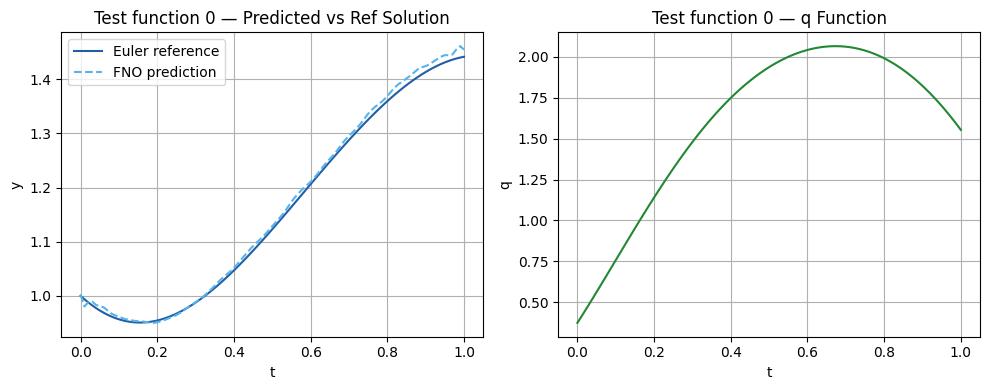

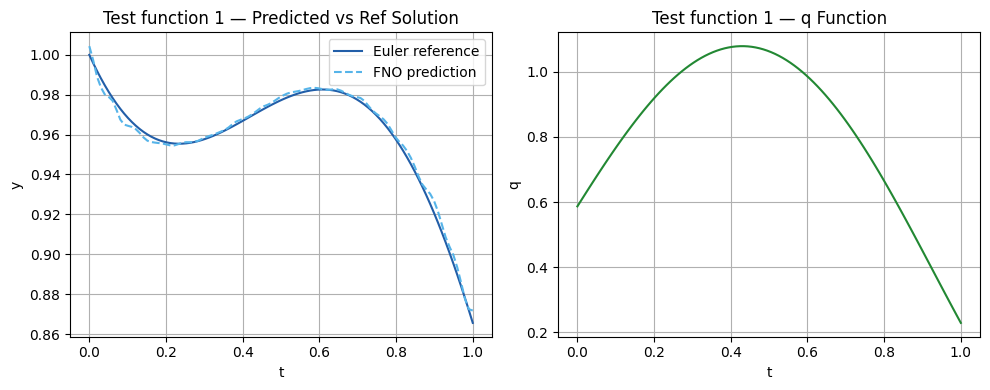

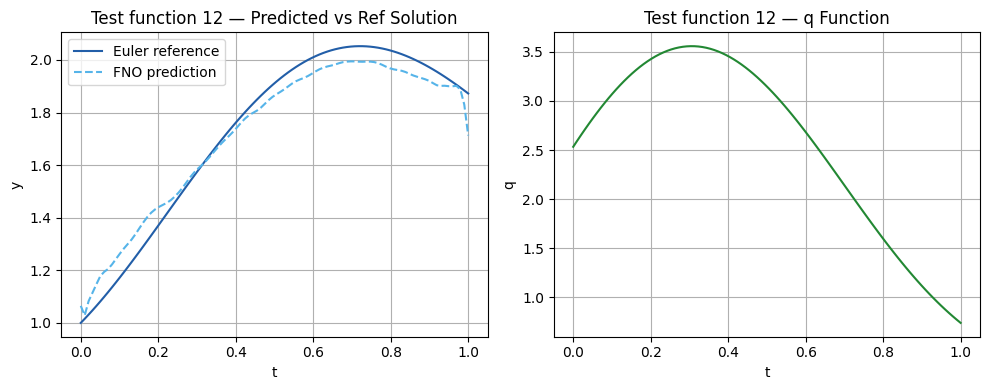

In [26]:
model.eval()
with torch.no_grad():
    test_predictions = model(q_test)

    # One MSE per test function, averaged over its time points.
    test_mse_per_function = torch.mean(
        (test_predictions - y_test) ** 2, dim=1
    )

test_mse = test_mse_per_function.mean().item()
worst_test_index = test_mse_per_function.argmax().item()

print(f"Mean test MSE:  {test_mse:.3e}")
print(f"Worst test MSE: {test_mse_per_function[worst_test_index].item():.3e}")

# Show two test functions and the function with the largest test MSE.
# dict.fromkeys removes a duplicate if the worst is already sample 0 or 1.
indices_to_plot = list(dict.fromkeys([0, 1, worst_test_index]))

for i in indices_to_plot:
    plot_pred_and_q(
        q_test[i],
        y_test[i],
        test_predictions[i],
        t_grid_q,
        title_prefix=f"Test function {i}",
    )

### Variability across training seeds

A fixed seed makes a run reproducible, but one run does not show how much the result depends on initialization and minibatch order.

Here we keep the training, validation, and test functions fixed and repeat training with three seeds. The spread describes variability due to these training choices for this fixed dataset. We use the test set only after fixing the model and training settings.

In [27]:
seeds = [1, 2, 3]

test_mses = []
train_histories = []
val_histories = []

for seed in seeds:
    if seed == 1:
        # Reuse the main run and its recorded history.
        seed_model = model
        seed_epochs = eval_epochs
        seed_train_mses = train_mses
        seed_val_mses = val_mses
    else:
        seed_model, seed_epochs, seed_train_mses, seed_val_mses = (
            train_one_model(seed=seed, verbose=False)
        )

    # All curves must be evaluated at the same epochs.
    assert seed_epochs == eval_epochs

    train_histories.append(seed_train_mses)
    val_histories.append(seed_val_mses)

    seed_test_mse = evaluate_mse(seed_model, q_test, y_test)
    test_mses.append(seed_test_mse)

    print(f"Seed {seed}: test MSE = {seed_test_mse:.3e}")

print(f"Mean test MSE: {np.mean(test_mses):.3e}")
print(f"Standard deviation: {np.std(test_mses, ddof=1):.3e}")

Seed 1: test MSE = 1.589e-04
Seed 2: test MSE = 4.975e-05
Seed 3: test MSE = 1.880e-04
Mean test MSE: 1.322e-04
Standard deviation: 7.288e-05


### Training curves across seeds

The lines show the mean training and validation MSE across the three runs. The shaded areas show one standard deviation above and below the mean.

The datasets are fixed across runs, so the shaded areas describe variability from initialization and minibatch order for these particular datasets. Three seeds provide only a rough indication of variability.

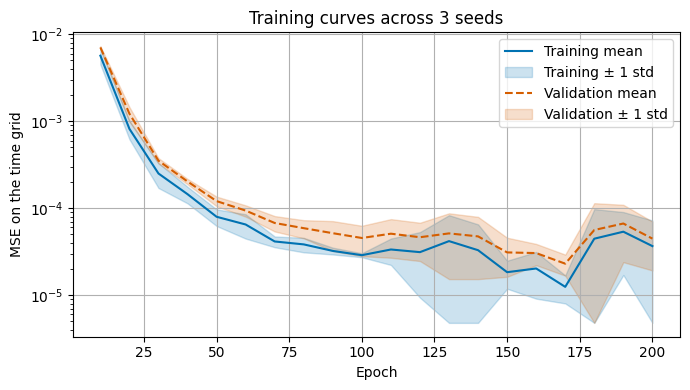

In [28]:
# Shape: (number of seeds, number of recorded epochs)
train_histories = np.array(train_histories)
val_histories = np.array(val_histories)

train_mean = train_histories.mean(axis=0)
train_std = train_histories.std(axis=0, ddof=1)

val_mean = val_histories.mean(axis=0)
val_std = val_histories.std(axis=0, ddof=1)

# A logarithmic axis cannot display zero or negative values.
# Clip the lower edge of a band if mean - std is not positive.
positive_values = np.concatenate([
    train_histories.ravel(),
    val_histories.ravel(),
])
plot_floor = max(
    np.min(positive_values[positive_values > 0]) / 2,
    np.finfo(float).tiny,
)

plt.figure(figsize=(7, 4))

plt.plot(eval_epochs, train_mean, color=TRAIN_COLOR, label="Training mean")
plt.fill_between(
    eval_epochs,
    np.maximum(train_mean - train_std, plot_floor),
    train_mean + train_std,
    color=TRAIN_COLOR,
    alpha=0.2,
    label="Training ± 1 std",
)

plt.plot(
    eval_epochs, val_mean,
    color=VAL_COLOR, linestyle="--", label="Validation mean"
)
plt.fill_between(
    eval_epochs,
    np.maximum(val_mean - val_std, plot_floor),
    val_mean + val_std,
    color=VAL_COLOR,
    alpha=0.2,
    label="Validation ± 1 std",
)

plt.yscale("log")
plt.xlabel("Epoch")
plt.ylabel("MSE on the time grid")
plt.title(f"Training curves across {len(seeds)} seeds")
plt.grid(True)
plt.legend()
plt.tight_layout()
plt.show()

## Exercise

Improve generalization capabability (performance on samples not seen during training). Ideas: more training samples, better architecture, better training, ...

# Zero-Shot Super Resolution

We now apply the trained model on a finer grid over the same time interval, without retraining. The input function must also be available on that finer grid.

The FFT treats its sampled input as one period of a periodic sequence. Our ODE grid includes both endpoints, and the input and solution need not be periodic. Therefore, changing the number of endpoint-inclusive grid points also changes the effective period associated with the discrete FFT. This example illustrates reuse of the learned parameters at a finer resolution.

## Test on a training sample but with higher resolution

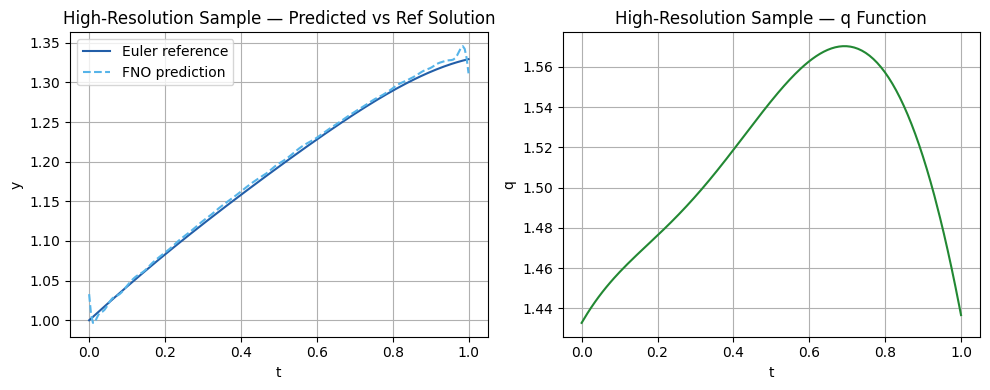

In [29]:
Nt_high = 200
t_grid_high = np.linspace(0, T, Nt_high)  # same domain length [0,1]

# Interpolate a training input onto the finer grid
q_high_np = np.interp(t_grid_high, t_grid_q.reshape(-1), q[0].cpu().numpy())
q_high = torch.from_numpy(q_high_np).float().unsqueeze(0).to(device)  # (1, Nt_high)

# Predict and compute reference solution
model.eval()
with torch.no_grad():
    y_high_pred = model(q_high).cpu().numpy().squeeze()
    y_high_ref = solve_ode_for_q(q_high_np, y0=y0, T=T, Nt=Nt_high)

# Plot everything using the helper
plot_pred_and_q(
    q_high_np,
    y_high_ref,
    y_high_pred,
    t_grid_high,
    title_prefix="High-Resolution Sample"
)


## Test on a new sample with higher resolution

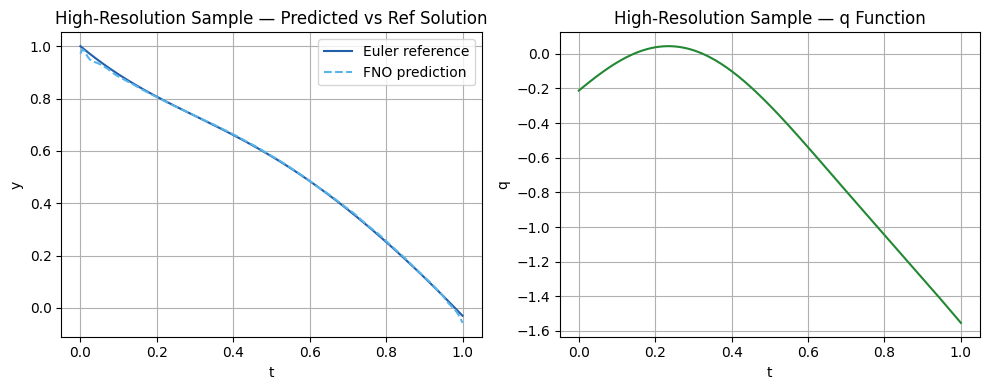

In [30]:
# Example: generate high-res q directly from GRF generator
Nt_high = 200
t_grid_high = np.linspace(0, T, Nt_high)  # same domain length [0,1]

# Generate high-res q
q_high_np = generate_grf_samples(1, grid_points=t_grid_high, ell=ell)[0]
q_high = torch.from_numpy(q_high_np).float().unsqueeze(0).to(device)  # (1, Nt_high)

# Predict and compute reference solution
model.eval()
with torch.no_grad():
    y_high_pred = model(q_high).cpu().numpy().squeeze()
    y_high_ref = solve_ode_for_q(q_high_np, y0=y0, T=T, Nt=Nt_high)

# Plot everything using the helper
plot_pred_and_q(
    q_high_np,
    y_high_ref,
    y_high_pred,
    t_grid_high,
    title_prefix="High-Resolution Sample"
)

### Comparing resolutions for the same input function

We generate one new function on a fine grid and use every other value to obtain its values on the coarse grid. We then apply the same trained model at both resolutions.

The two Euler reference solutions also use different step sizes, so a difference in error can reflect both the model evaluation and the reference discretization.

Coarse-grid MSE (100 points): 7.952e-05
Fine-grid MSE (199 points):   9.643e-05


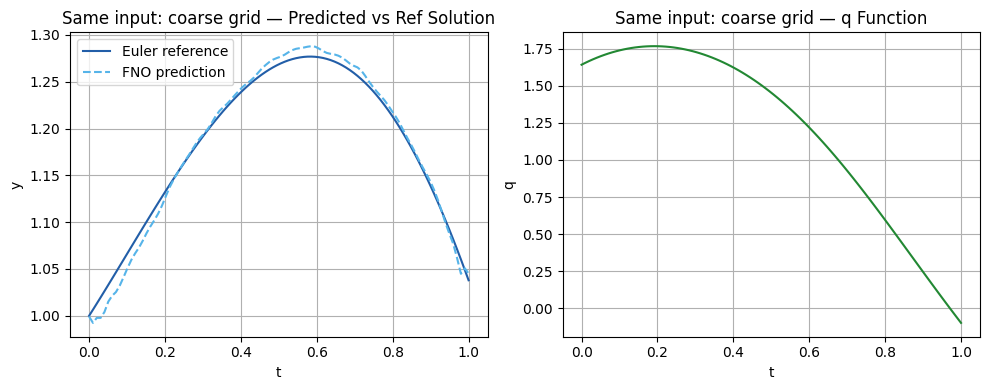

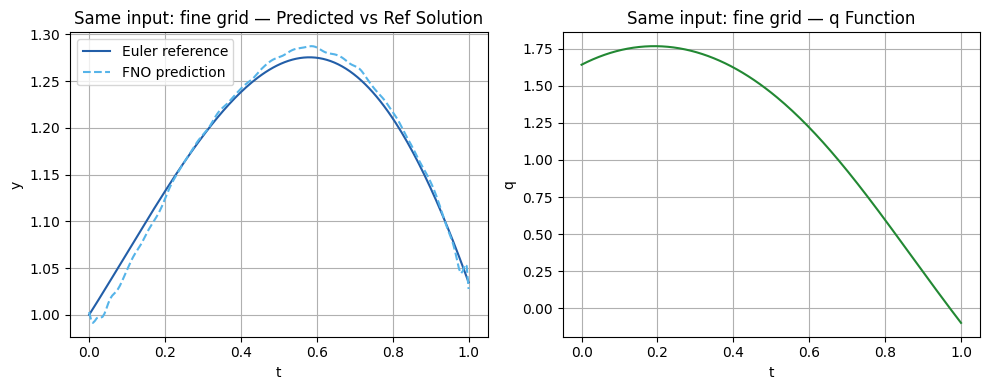

In [32]:
# With 100 coarse points, 199 fine points produce nested grids.
Nt_fine = 2 * Nt_q - 1
t_fine = np.linspace(0, T, Nt_fine)

# Generate one new input on the fine grid.
q_fine_np = generate_grf_samples(1, t_fine, ell=ell)[0]

# Every other fine-grid point is a coarse-grid point.
# TODO: Select every other value of the fine-grid input.
q_coarse_np = q_fine_np[::2]

# Euler references use the corresponding time steps.
y_coarse_ref = solve_ode_for_q(q_coarse_np, y0=y0, T=T, Nt=Nt_q)
y_fine_ref = solve_ode_for_q(q_fine_np, y0=y0, T=T, Nt=Nt_fine)

q_coarse = torch.tensor(
    q_coarse_np, dtype=torch.float32, device=device
).unsqueeze(0)

q_fine = torch.tensor(
    q_fine_np, dtype=torch.float32, device=device
).unsqueeze(0)

model.eval()
with torch.no_grad():
    y_coarse_pred = model(q_coarse).squeeze(0).cpu().numpy()
    y_fine_pred = model(q_fine).squeeze(0).cpu().numpy()

coarse_mse = np.mean((y_coarse_pred - y_coarse_ref) ** 2)
fine_mse = np.mean((y_fine_pred - y_fine_ref) ** 2)

print(f"Coarse-grid MSE ({Nt_q} points): {coarse_mse:.3e}")
print(f"Fine-grid MSE ({Nt_fine} points):   {fine_mse:.3e}")

plot_pred_and_q(
    q_coarse_np, y_coarse_ref, y_coarse_pred, t_grid_q,
    title_prefix="Same input: coarse grid"
)

plot_pred_and_q(
    q_fine_np, y_fine_ref, y_fine_pred, t_fine,
    title_prefix="Same input: fine grid"
)

## Exercise

Improve the results of zero-shot super resolution.